# Tutorial: Supervised Learning Problem and Least Squares

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/git/https%3A%2F%2Fgitlab.in2p3.fr%2Fenergy4climate%2Fpublic%2Feducation%2Fmachine_learning_for_climate_and_energy/master?filepath=book%2Fnotebooks%2F02_tutorial_supervised_learning_problem_ols.ipynb)

Tutorial to the classes [Supervised Learning Problem and Least Squares](02_supervised_learning_problem.ipynb) and [Ordinary Least Squares](03_ordinary_least_squares.ipynb).

<div class="alert alert-block alert-info">
    <b>Tutorial Objectives</b>
    
- Read, plot and analyze train data
- Use supervised learning to predict the regional electricity consumption of France in response electric heating based on temperature data
- Test the linear least squares (OLS) model
- Evaluate their performance by estimating their Expected Prediction Errors (EPE) using test data
</div>

## Dataset presentation

- Input:
  - 2m-temperature
    - Domain: Metropolitan France
    - Spatial resolution: regional average
    - Time resolution: hourly
    - Period: 2014-2021
    - Units: °C
    - Source: [MERRA-2 reanalysis](https://gmao.gsfc.nasa.gov/reanalysis/MERRA-2/)
- Target:
  - Electricity demand
    - Domain: Metropolitan France
    - Spatial resolution: regional sum
    - Time resolution: hourly
    - Period: 2014-2021
    - Units: MWh
    - Source: [RTE](https://opendata.reseaux-energies.fr/)

## Reading and pre-analysis of the input and output data

### Import data-analysis and plot modules and define paths

In [2]:
# Path manipulation module
from pathlib import Path
# Numerical analysis module
import numpy as np
# Formatted numerical analysis module
import pandas as pd
# Plot module
import matplotlib.pyplot as plt
# Default colors
RC_COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']
# Matplotlib configuration
plt.rc('font', size=14)

In [3]:
# Set data directory
data_dir = Path('data')

# Set keyword arguments for pd.read_csv
kwargs_read_csv = dict()

# Set first and last years
FIRST_YEAR = 2014
LAST_YEAR = 2021

# Define temperature filepath
temp_filename = 'surface_temperature_merra2_{}-{}.csv'.format(
    FIRST_YEAR, LAST_YEAR)
temp_filepath = Path(data_dir, temp_filename)
temp_label = 'Temperature (°C)'

# Define electricity demand filepath
dem_filename = 'reseaux_energies_demand_demand.csv'
dem_filepath = Path(data_dir, dem_filename)
dem_label = 'Electricity consumption (MWh)'

### Reading and plotting the raw temperature data

> ***Question (code cells below)***
> - Use `pd.read_csv` with the filepath and appropriate options to make sure to get the column names and the index as dates (`DatetimeIndex`).
> - Use the `resample` method from the data frame to compute daily means.
> - Plot the `'Île-de-France'` daily-mean temperature time series for (a) the whole period, (b) one year, (c) one month in winter and (d) one month in summer on 4 different figures (use `plt.figure`) using `plt.plot` or the `plot` method from data frames (preferably).
> - Use the `mean` and `var` methods to get mean and variance of the daily-mean temperature.

In [4]:
# answer cell
df = pd.read_csv(temp_filepath,index_col=0, parse_dates=True, header=0)
df_daily_mean = df.resample('D').mean()
df_daily_mean

,Grand Est,Nouvelle-Aquitaine,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Île-de-France,Occitanie,Hauts-de-France,Normandie,Pays de la Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2014-01-01 00:00:00+00:00,5.107484,7.744094,4.078089,5.446240,9.919296,7.041969,6.840232,7.272172,6.199675,6.790155,9.074595,4.473602
2014-01-02 00:00:00+00:00,6.719443,9.848356,5.515910,7.172765,9.592866,8.541166,8.002626,8.944517,7.665501,7.903015,9.578815,6.015902
2014-01-03 00:00:00+00:00,6.985850,10.277304,5.837213,7.116027,9.998016,9.349040,8.967253,9.246156,8.491202,8.618359,10.476716,6.238458
2014-01-04 00:00:00+00:00,5.434065,8.248889,5.935265,6.313470,7.866493,7.681166,7.203723,7.907478,6.780090,6.577409,7.787745,7.008832
2014-01-05 00:00:00+00:00,3.507003,7.077702,2.327924,4.105760,9.238308,6.058866,4.913896,5.610716,4.494479,5.948081,8.501738,3.599627
...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-27 00:00:00+00:00,6.264867,11.098441,5.760234,6.612773,11.578724,9.628563,8.509613,9.783560,7.623578,9.750202,11.152485,6.330366
2021-12-28 00:00:00+00:00,8.496452,12.497289,8.049788,9.024312,11.476599,10.888126,10.146316,11.601026,9.720647,9.955050,11.629119,7.507243
2021-12-29 00:00:00+00:00,9.044886,12.888432,9.734367,10.199146,13.087657,12.395462,11.093337,12.262475,10.453279,11.924924,12.924623,10.475215


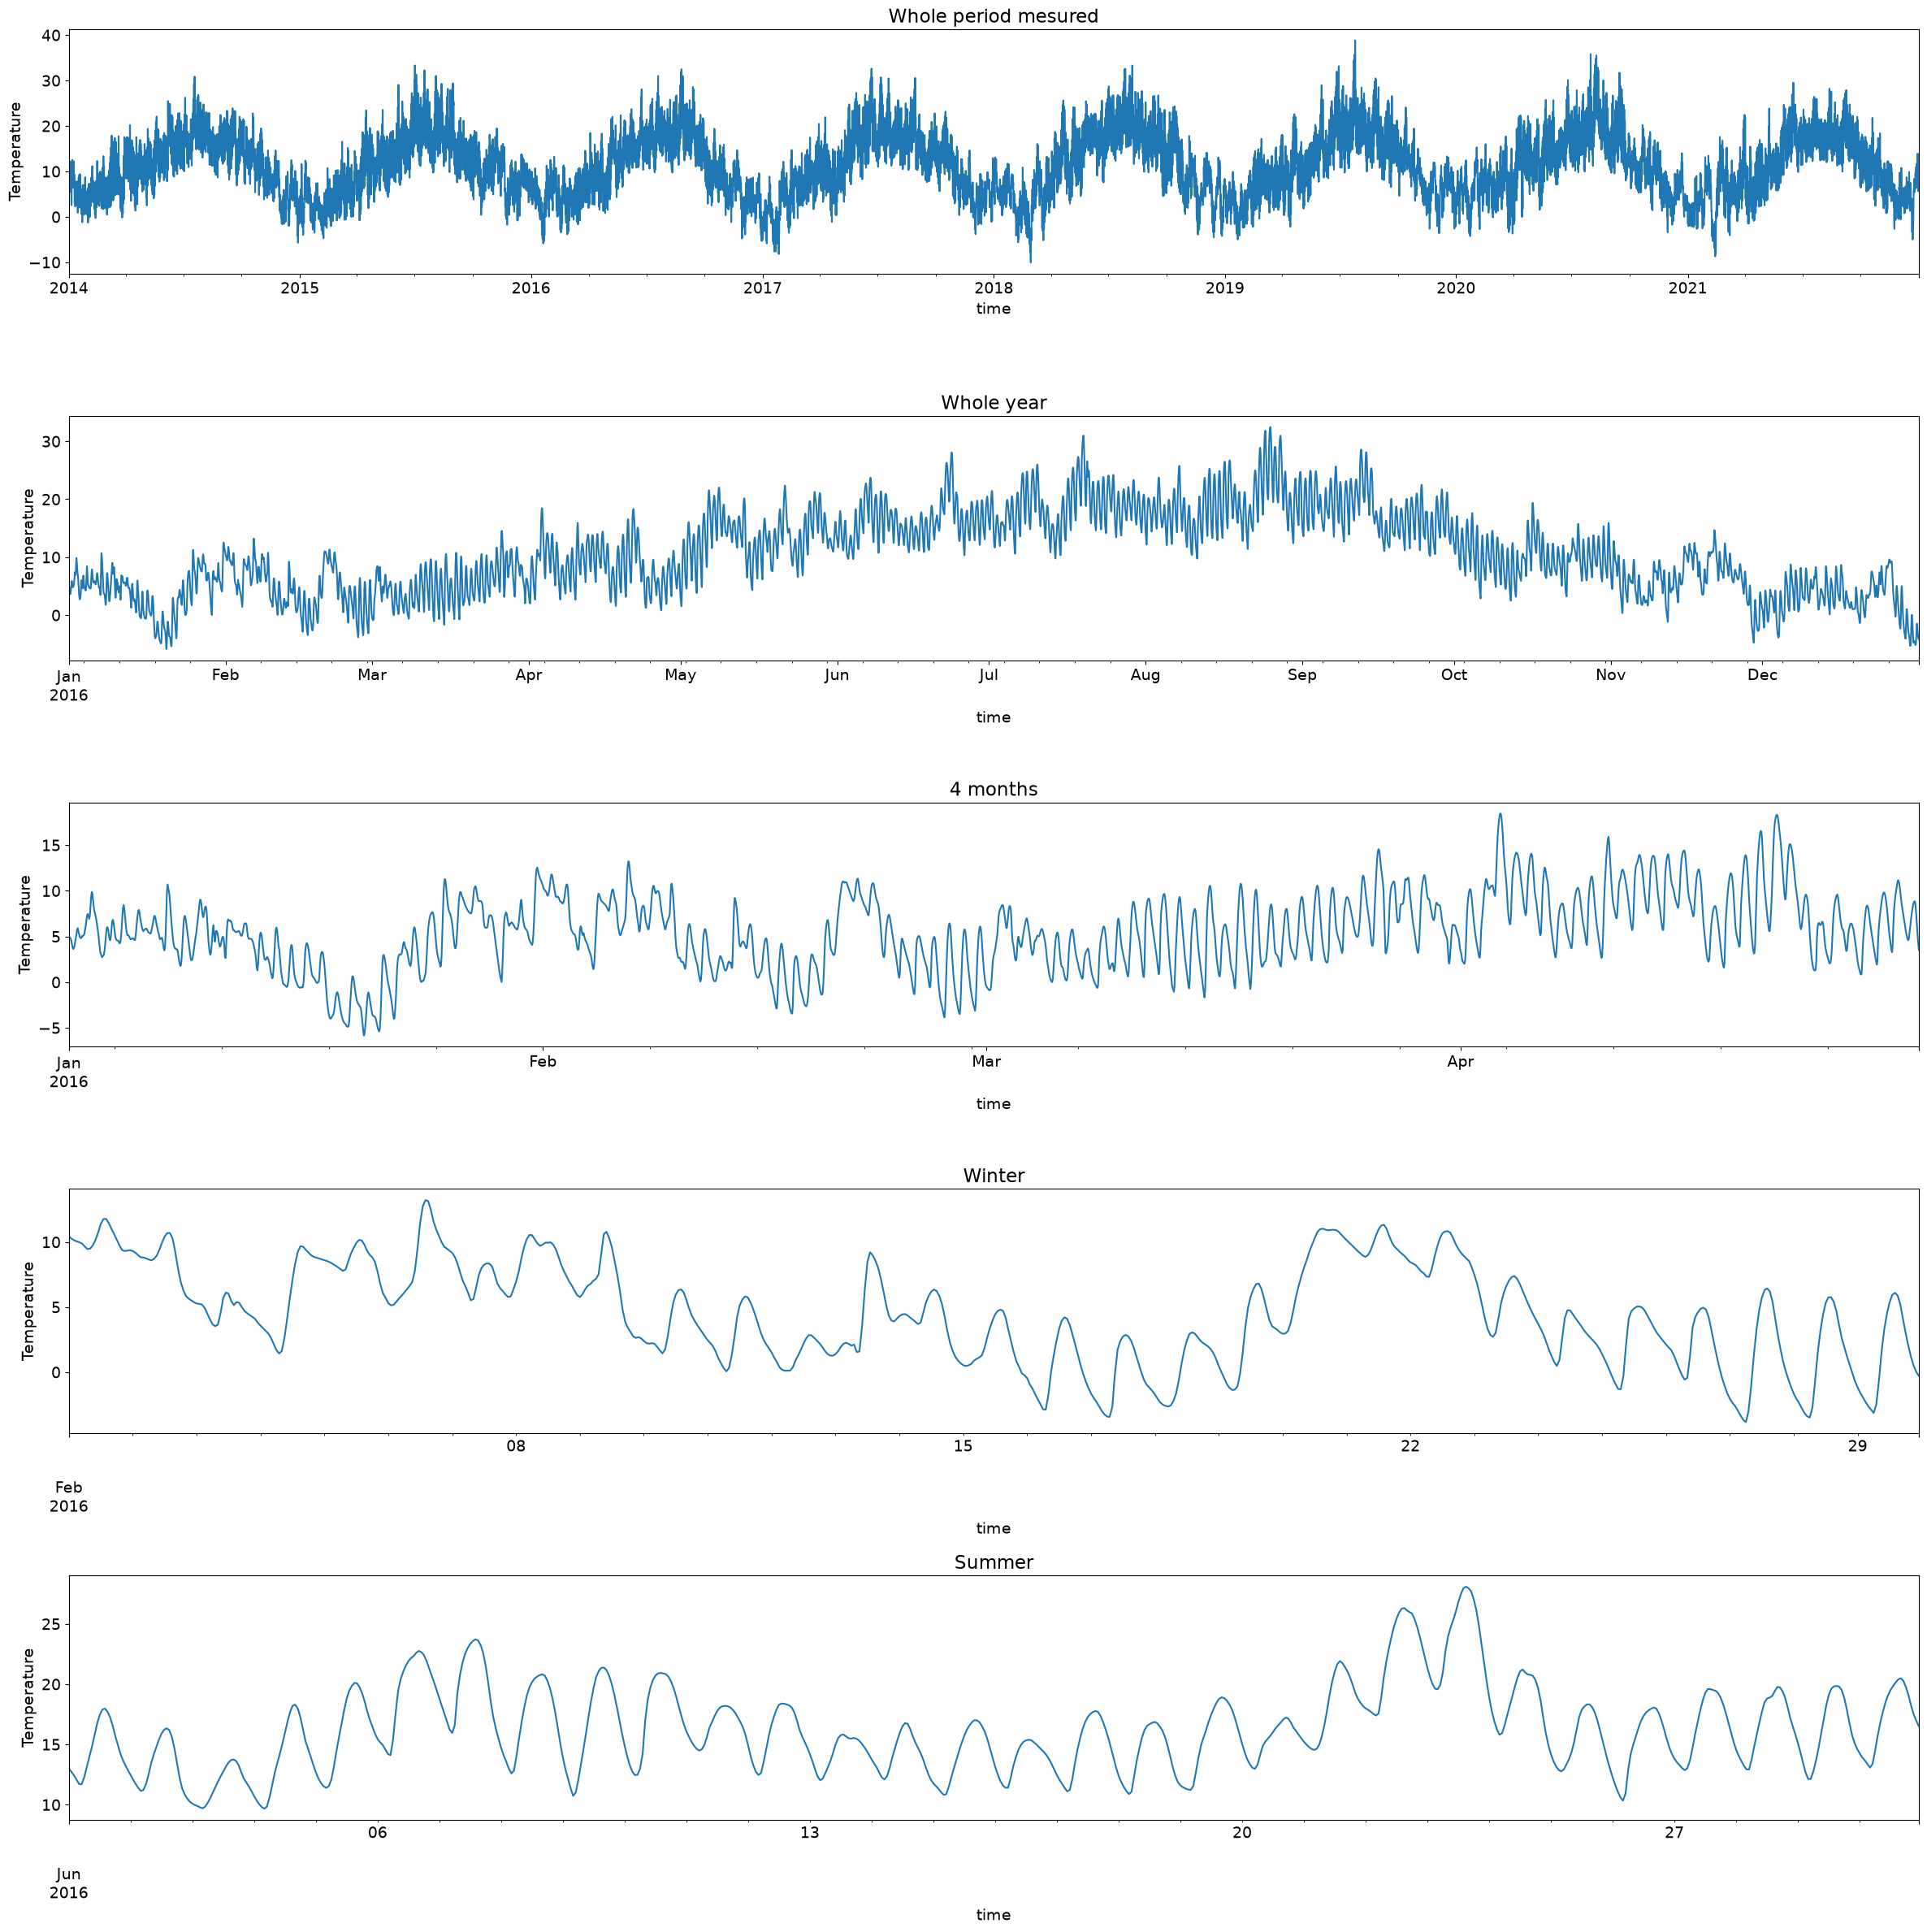

In [5]:
# Select Île-de-France region
region_name = 'Île-de-France'

# Select Île-de-France region
region_name = 'Île-de-France'
df_idf = df[region_name]

#1 year
date0,date1 = "2016-01","2016-12"
#4 months
date2 = "2016-04"
#Winter
date3 = "2016-02"
#Summer
date4 = "2016-06"
fig, ax = plt.subplots(5,1,figsize = (24,24))
df_idf.plot(ax=ax[0], title = "Whole period mesured")
df_idf.loc[date0:date1].plot(ax = ax[1], title= "Whole year")
df_idf.loc[date0:date2].plot(ax = ax[2], title = "4 months")
df_idf.loc[date3].plot(ax = ax[3], title = "Winter")
df_idf.loc[date4].plot(ax = ax[4], title = "Summer")
for i in range(5): ax[i].set_ylabel("Temperature")
plt.tight_layout()
plt.show()

### Reading and plotting the demand data

> ***Question***
> - Same question for the demand but with daily sums instead of daily means

In [6]:
# answer cell
demande = pd.read_csv(dem_filepath,parse_dates=True, header=0,index_col = 0)
demande_daily_sum = demande.resample('D').sum()
demande_daily_sum


,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Île-de-France,Normandie,Nouvelle-Aquitaine,Occitanie,Pays de la Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2014-01-01 00:00:00+00:00,366369,112798,132433,110689,231295,277961,423100,157801,253257,229813,155858,269608
2014-01-02 00:00:00+00:00,399410,124601,144919,118617,260432,301955,455859,167222,263474,233452,168902,274686
2014-01-03 00:00:00+00:00,411039,130114,146564,119101,268670,314263,450949,171729,264560,235601,170268,272650
2014-01-04 00:00:00+00:00,382822,121803,142266,113768,253251,303556,425710,164949,262030,219141,164340,256300
2014-01-05 00:00:00+00:00,378138,119063,137725,114905,243481,298241,431656,167316,265687,222565,161560,252031
...,...,...,...,...,...,...,...,...,...,...,...,...
2021-12-27 00:00:00+00:00,410482,122840,139050,112456,238779,280594,404518,156761,255465,235059,156076,269762
2021-12-28 00:00:00+00:00,402913,123658,140059,123495,244126,285320,390630,155491,249163,228643,154361,264109
2021-12-29 00:00:00+00:00,389557,117573,134461,118070,237856,279507,383158,151769,240814,211393,149452,243514


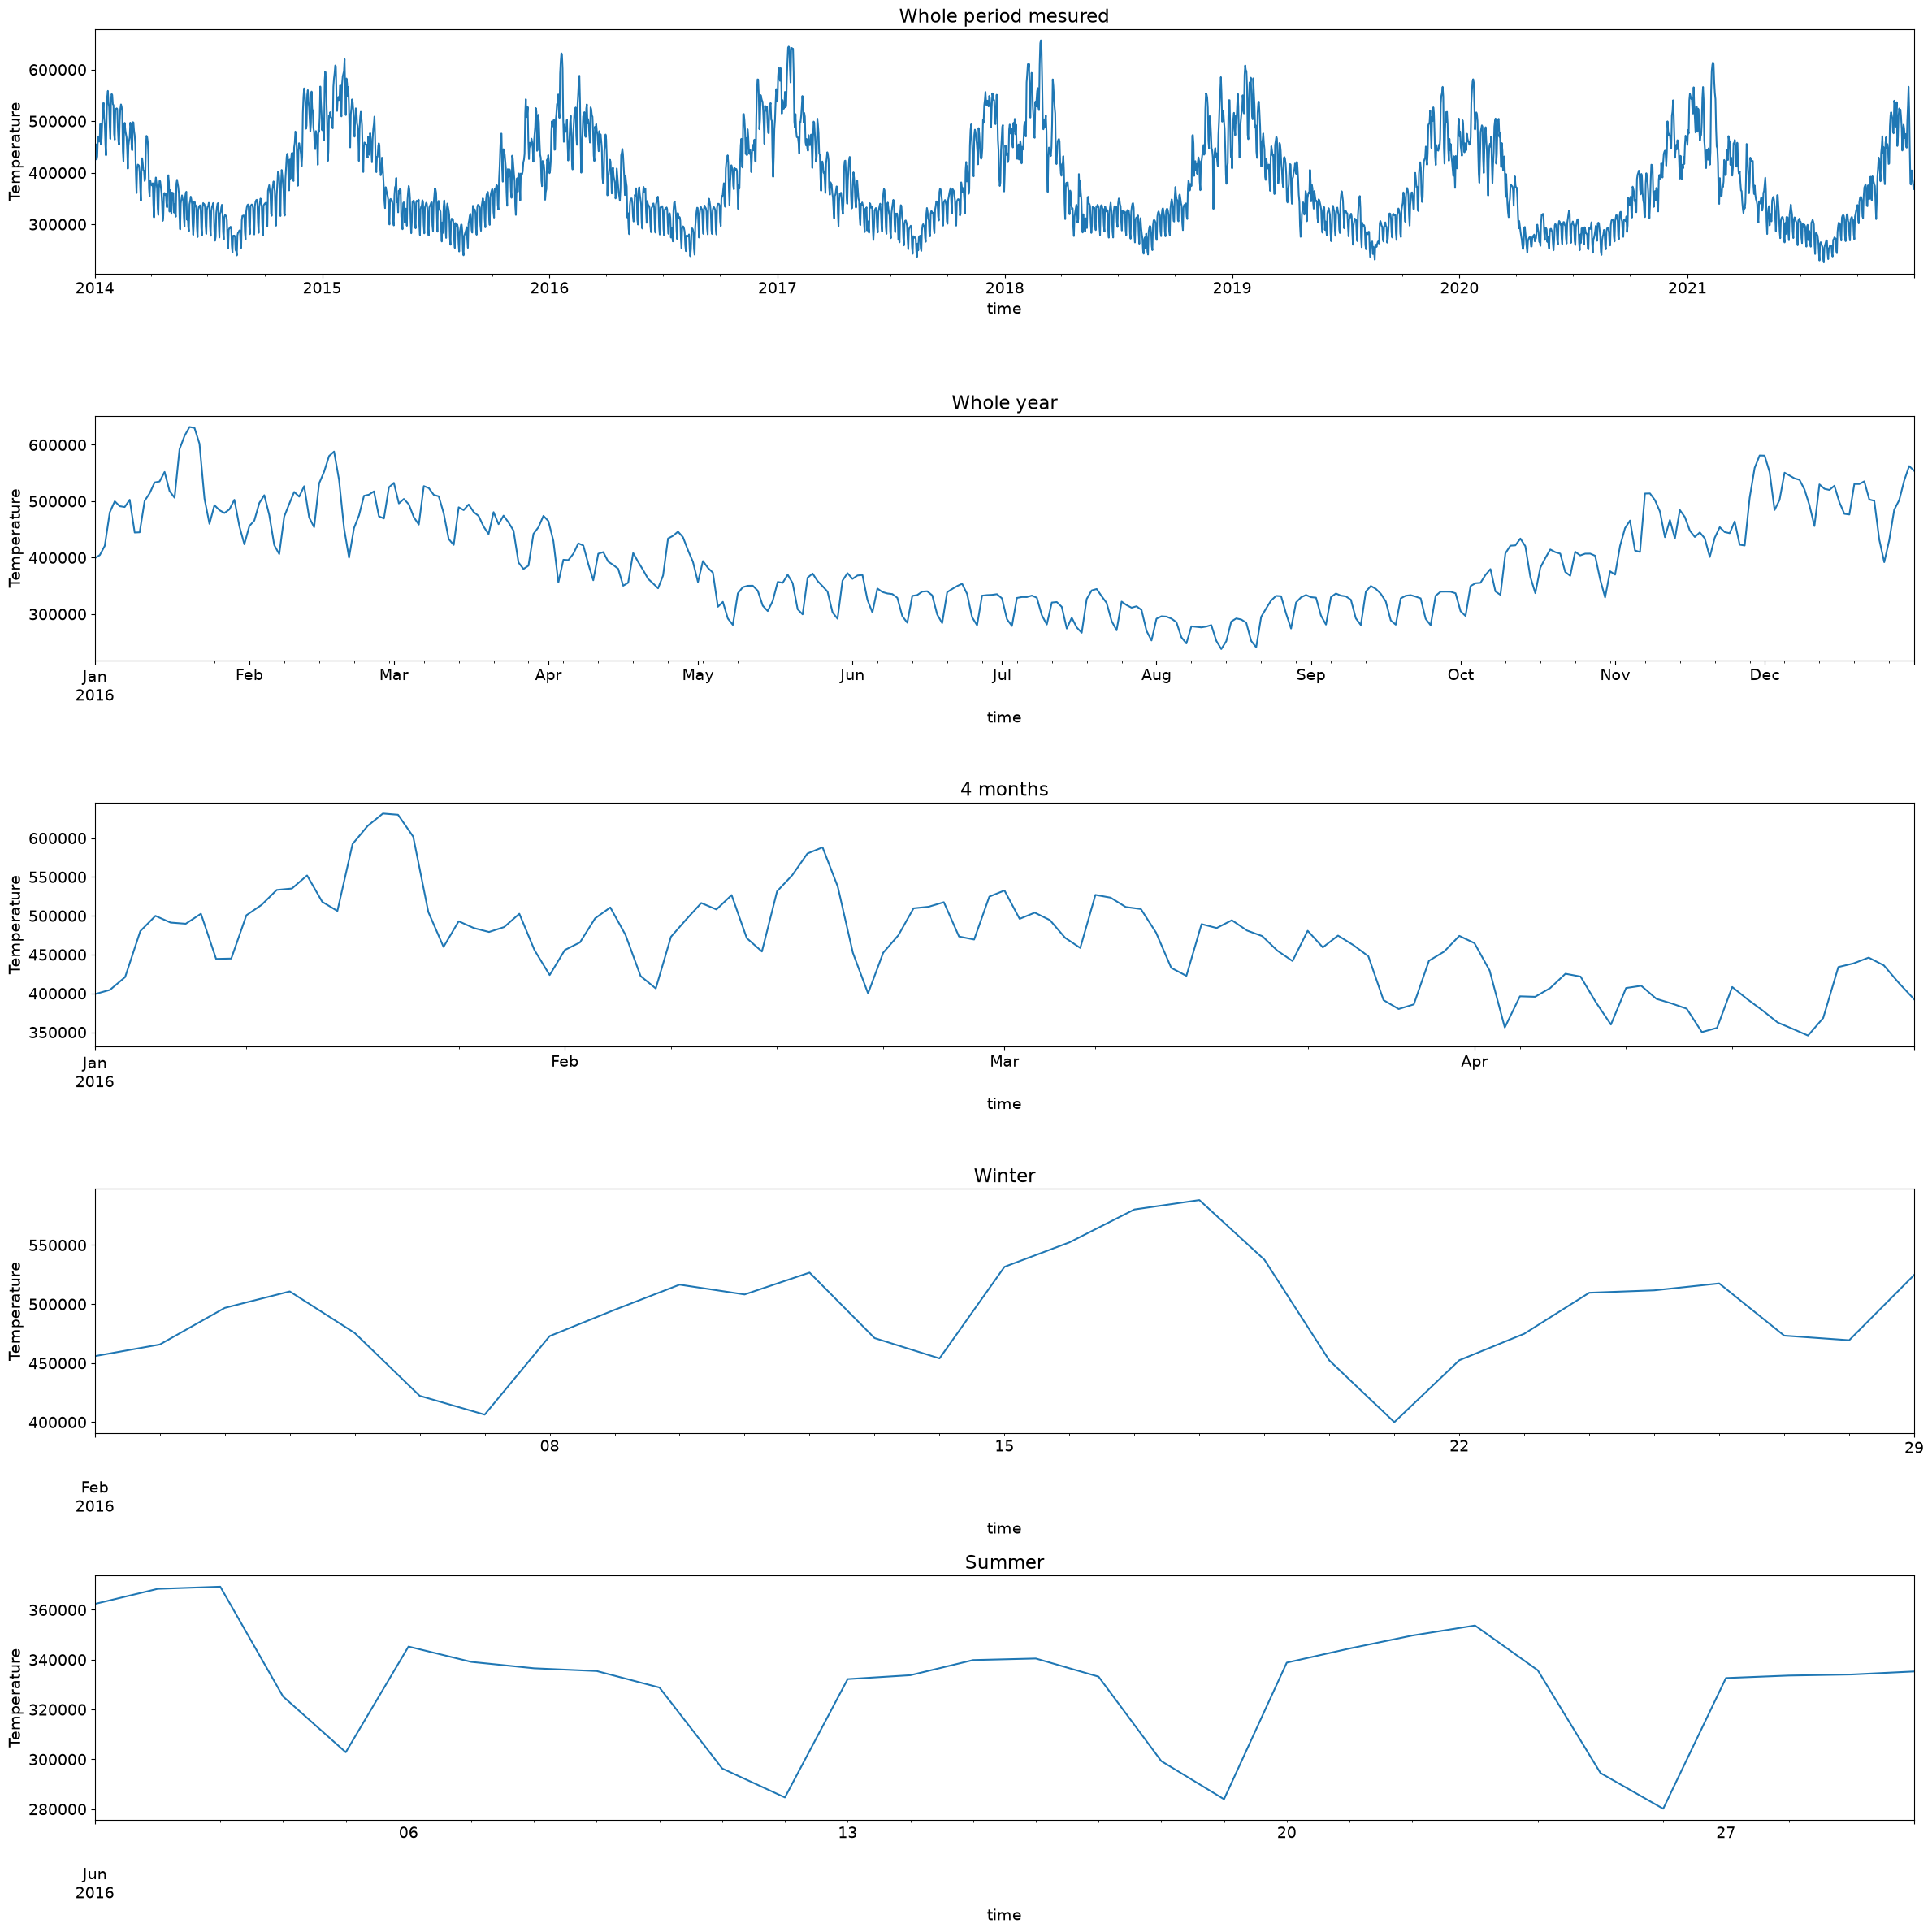

Mean:
Auvergne-Rhône-Alpes          359930.147844
Bourgogne-Franche-Comté       116251.868241
Bretagne                      121982.780630
Centre-Val de Loire           102566.467146
Grand Est                     247762.174880
Hauts-de-France               275284.629021
Île-de-France                 383296.134497
Normandie                     151590.188569
Nouvelle-Aquitaine            236348.120123
Occitanie                     204540.816222
Pays de la Loire              147416.973990
Provence-Alpes-Côte d'Azur    222933.334702
dtype: float64

Variance:
Auvergne-Rhône-Alpes          4.770630e+09
Bourgogne-Franche-Comté       5.725151e+08
Bretagne                      8.257339e+08
Centre-Val de Loire           6.001391e+08
Grand Est                     2.044673e+09
Hauts-de-France               2.341267e+09
Île-de-France                 7.749292e+09
Normandie                     1.015336e+09
Nouvelle-Aquitaine            2.436175e+09
Occitanie                     1.959895e+09
Pays de la

In [7]:
# Select Île-de-France region
region_name = 'Île-de-France'
df_dem_idf = demande_daily_sum[region_name]

#1 year
date0,date1 = "2016-01","2016-12"
#4 months
date2 = "2016-04"
#Winter
date3 = "2016-02"
#Summer
date4 = "2016-06"
fig, ax = plt.subplots(5,1,figsize = (24,24))
df_dem_idf.plot(ax=ax[0], title = "Whole period mesured")
df_dem_idf.loc[date0:date1].plot(ax = ax[1], title= "Whole year")
df_dem_idf.loc[date0:date2].plot(ax = ax[2], title = "4 months")
df_dem_idf.loc[date3].plot(ax = ax[3], title = "Winter")
df_dem_idf.loc[date4].plot(ax = ax[4], title = "Summer")
for i in range(5): ax[i].set_ylabel("Temperature")
plt.tight_layout()
plt.show()

# Compute mean and variance of daily demerature
print('Mean:')
print(demande_daily_sum.mean())
print('\nVariance:')
print(demande_daily_sum.var())

### Analyzing the input and target data and their relationships

> ***Question (write your answer in text box below)***
> - Describe the seasonality of the temperature in Île-de-France.
> - Are all years the same?
> - Describe the seasonal and weakly demand patterns.

Answer:

> ***Question***
> - Select the temperature and demand data for their largest common period using the `intersection` method of the `index` attribute of the data frames.
> - Represent a scatter plot of the daily demand versus the daily temperature using `plt.scatter`.

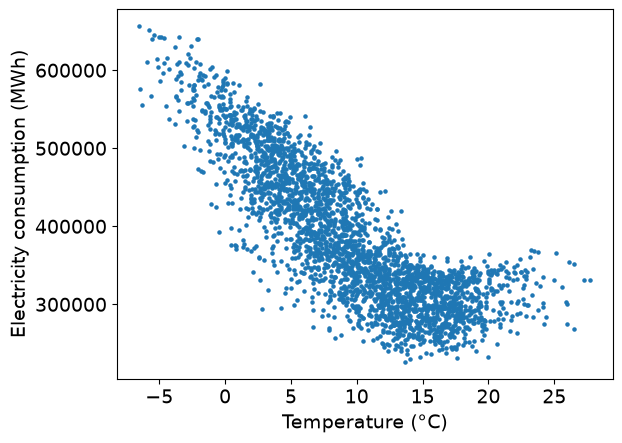

In [8]:
# answer cell
# Select the temperature and the demand data for their largest common period
# Solution 1
common_index = df_dem_idf.index.intersection(df_idf.index)
df_dem_idf = df_dem_idf.loc[common_index]
df_temp_idf = df_idf.loc[common_index]

plt.scatter(df_temp_idf,df_dem_idf,s = 5)
plt.xlabel(temp_label)
plt.ylabel(dem_label)
plt.show()


> ***Question***
> - Compute the correlation between the daily temperature and the daily demand in Île-de-France using `np.corrcoef`.
> - Compute the correlation between the monthly temperature and the monthly demand using the `resample` method.
> - What do you think explains the difference between the daily and the monthly correlation?

In [18]:
# answer cell
correlation = np.corrcoef(df_temp_idf,df_dem_idf)
#ME: Month End | MS: Month start
correlation_monthly = np.corrcoef(df_temp_idf.resample("MS").mean(),df_dem_idf.resample("MS").sum()) 

print(f"Monthly correlation: {correlation_monthly[0,1]}\n Daily correlation: {correlation[0,1]}")

Monthly correlation: -0.9273192285269766
 Daily correlation: -0.8293140292668261


Answer:

## Ordinary Least Squares

> ***Question***
> - Perform an OLS with intercept using the entire dataset from the temperature using the formula for the optimal coefficients derived in [Supervised Learning Problem and Least Squares](2_supervised_learning_problem_ols.ipynb) (without Scikit-Learn). To do so:
>   - Prepare the input matrix and output vector with the `np.concatenate` function (for instance);
>   - Use the matrix-multiplication operator seen in [Introduction](1_introduction.ipynb) and the `np.linalg.inv` function to compute the optimal coefficients and print them.
> - Use the estimated coefficents to predict the target from the input train data.
> - Overlay your prediction to the scatter plot of the train data.
> - Compute the train Mean Squared Error (MSE) and the train coefficient of determination ($R^2$) and print them.

In [10]:
# answer cell


> ***Question***
> - Compute the optimal coefficients using centered input temperatures.
> - Compute the optimal intercept alone using a single-column input matrix.
> - Compare the resulting two estimations of the intercept with the sample mean of the target train data.

In [11]:
# answer cell


> ***Question***
> - Perform an OLS fit with intercept using the entire dataset to predict the demand from the temperature using Scikit-learn. To do so:
>   - Import the `linear_model` module from `sklearn` (Scikit-Learn)
>   - Define a regressor using `linear_model.LinearRegression` (by default, the regressor is configured to fit an intercept in addition to the features, see `fit_intercept` option)
>   - Prepare the input matrix and output vector for the `fit` method of the regressor
>   - Apply the `fit` method to the input and output
> - Print the fitted coefficients using the `coef_` attribute of the regressor.
> - Compute the train $R^2$ coefficient using the `score` method of the regressor.
> - Compare the resulting coefficients and score to those obtained above by applying the formulas yourself.

In [12]:
# answer cell


Answer: 

> ***Question***
> - Define and array of 100 temperatures ranging from -5 to 35°C with `np.linspace`.
> - Make a prediction of the demand for these temperatures using the trained OLS model with the `predict` method of the regressor.
> - Plot this prediction over the scatter plot of the train data.
> - Does the demand prediction seem satisfactory over the whole range of temperatures?

In [13]:
# answer cell


Answer:

***
## Credit

[//]: # "This notebook is part of [E4C Interdisciplinary Center - Education](https://gitlab.in2p3.fr/energy4climate/public/education)."
Contributors include Bruno Deremble and Alexis Tantet.
Several slides and images are taken from the very good [Scikit-learn course](https://inria.github.io/scikit-learn-mooc/).

<br>

<div style="display: flex; height: 70px">
    
<img alt="Logo LMD" src="images/logos/logo_lmd.jpg" style="display: inline-block"/>

<img alt="Logo IPSL" src="images/logos/logo_ipsl.png" style="display: inline-block"/>

<img alt="Logo E4C" src="images/logos/logo_e4c_final.png" style="display: inline-block"/>

<img alt="Logo EP" src="images/logos/logo_ep.png" style="display: inline-block"/>

<img alt="Logo SU" src="images/logos/logo_su.png" style="display: inline-block"/>

<img alt="Logo ENS" src="images/logos/logo_ens.jpg" style="display: inline-block"/>

<img alt="Logo CNRS" src="images/logos/logo_cnrs.png" style="display: inline-block"/>
    
</div>

<hr>

<div style="display: flex">
    <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons License" style="border-width:0; margin-right: 10px" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a>
    <br>This work is licensed under a &nbsp; <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons Attribution-ShareAlike 4.0 International License</a>.
</div>